# Chapter 17: Reporting Your Findings

Companion notebook for *Master Exploratory Data Analysis: A Hands-On Beginner's Guide with Python, Statistics & A/B Testing*.

Run the cells from top to bottom (**Kernel → Restart Kernel and Run All Cells**). The data files are in the same folder as this notebook.

## 17.1 From Notebook to Report

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import (
    proportions_ztest, proportion_confint, confint_proportions_2indep)

plt.style.use('book.mplstyle')


def p_text(p):
    return 'p < 0.001' if p < 0.001 else f'p = {p:.3f}'


visitors = pd.read_csv('ab_test.csv', parse_dates=['visit_date'])
customers = pd.read_csv('customers.csv', parse_dates=['signup_date'])
orders = pd.read_csv('orders.csv', parse_dates=['order_date'])
cancellations = pd.read_csv('cancellations.csv',
                            parse_dates=['cancel_date'])
customers['cancelled'] = customers['customer_id'].isin(
    cancellations['customer_id'])

In [2]:
buyers = visitors.groupby('group')['purchased'].agg(
    ['sum', 'count', 'mean'])
buyers

,sum,count,mean
group,,,
control,911,11386,0.080011
new,1064,11370,0.093580


## 17.2 Answer First, Then One Chart and One Number

In [3]:
buyers = buyers.loc[['new', 'control']]
new, old = buyers.loc['new'], buyers.loc['control']
z_stat, p_value = proportions_ztest(buyers['sum'], buyers['count'])
gain_low, gain_high = confint_proportions_2indep(
    new['sum'], new['count'], old['sum'], old['count'])
gain = new['mean'] - old['mean']
print(f'Old page {old["mean"]:.1%}, new page {new["mean"]:.1%}')
print(f'Gain {gain * 100:.1f} points, 95% CI {gain_low * 100:.1f} '
      f'to {gain_high * 100:.1f} points, {p_text(p_value)}')
print(f'Relative lift: {gain / old["mean"]:.0%}')

Old page 8.0%, new page 9.4%
Gain 1.4 points, 95% CI 0.6 to 2.1 points, p < 0.001
Relative lift: 17%


### Translating into money

In [4]:
visitors['revenue'] = visitors['order_value'].fillna(0)
new_rev = visitors.loc[visitors['group'] == 'new', 'revenue']
old_rev = visitors.loc[visitors['group'] == 'control', 'revenue']
rev_test = stats.ttest_ind(new_rev, old_rev, equal_var=False)
rev_ci = rev_test.confidence_interval()
rev_gain = new_rev.mean() - old_rev.mean()
n_all = len(visitors)
print(f'Per visitor: ${rev_gain:.2f}, '
      f'95% CI ${rev_ci.low:.2f} to ${rev_ci.high:.2f}, '
      f'{p_text(rev_test.pvalue)}')
print(f'All {n_all:,} visitors: ${rev_gain * n_all:,.0f} '
      f'(${rev_ci.low * n_all:,.0f} to ${rev_ci.high * n_all:,.0f})')

Per visitor: $0.45, 95% CI $0.20 to $0.70, p < 0.001
All 22,756 visitors: $10,202 ($4,442 to $15,963)


### One chart

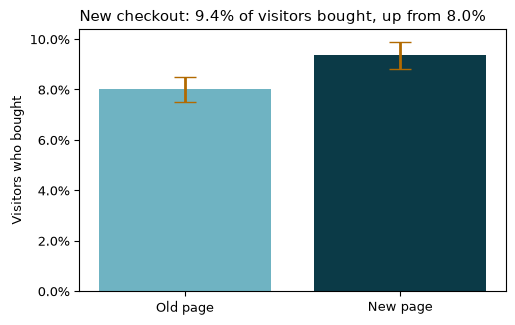

In [5]:
pages = buyers.loc[['control', 'new']]
low, high = proportion_confint(pages['sum'], pages['count'])
fig, ax = plt.subplots()
ax.bar(['Old page', 'New page'], pages['mean'],
       color=['#6fb3c2', '#0b3a47'],
       yerr=[pages['mean'] - low, high - pages['mean']],
       ecolor='#b26a00', capsize=8)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_title('New checkout: 9.4% of visitors bought, up from 8.0%')
ax.set_ylabel('Visitors who bought')
plt.show()

## 17.3 Saying How Sure You Are

### Big, small, or not enough evidence

In [6]:
new_orders = visitors.loc[visitors['group'] == 'new',
                          'order_value'].dropna()
old_orders = visitors.loc[visitors['group'] == 'control',
                          'order_value'].dropna()
value_test = stats.ttest_ind(new_orders, old_orders, equal_var=False)
value_ci = value_test.confidence_interval()
print(f'New minus old: ${new_orders.mean() - old_orders.mean():.2f}, '
      f'95% CI ${value_ci.low:.2f} to ${value_ci.high:.2f}, '
      f'{p_text(value_test.pvalue)}')

New minus old: $0.12, 95% CI $-0.94 to $1.18, p = 0.820


In [7]:
spend = orders.groupby('customer_id')['amount'].sum()
customers['total_spend'] = customers['customer_id'].map(spend)
with_age = customers.dropna(subset=['age'])
age_spend = stats.pearsonr(with_age['age'], with_age['total_spend'])
r_ci = age_spend.confidence_interval()
print(f'r = {age_spend.statistic:.2f}, '
      f'95% CI {r_ci.low:.2f} to {r_ci.high:.2f}, '
      f'{p_text(age_spend.pvalue)}')

r = 0.10, 95% CI 0.07 to 0.13, p < 0.001


## 17.4 Turning Numbers into Sentences

### The checkout test

In [8]:
print(f'The new checkout raised purchases from {old["mean"]:.1%} '
      f'to {new["mean"]:.1%} of visitors')
print(f'(95% CI for the gain: {gain_low * 100:.1f} to '
      f'{gain_high * 100:.1f} points; {p_text(p_value)}).')

The new checkout raised purchases from 8.0% to 9.4% of visitors
(95% CI for the gain: 0.6 to 2.1 points; p < 0.001).


### Plan and cancelling

In [9]:
plan_cancel = pd.crosstab(customers['plan'], customers['cancelled'])
plan_test = stats.chi2_contingency(plan_cancel)
plan_rates = customers.groupby('plan')['cancelled'].mean()
print(f'Basic {plan_rates["Basic"]:.0%}, '
      f'Standard {plan_rates["Standard"]:.0%}, '
      f'Premium {plan_rates["Premium"]:.0%}')
print(f"{p_text(plan_test.pvalue)}, Cramér's V = "
      f'{stats.contingency.association(plan_cancel):.2f}')

Basic 70%, Standard 49%, Premium 37%
p < 0.001, Cramér's V = 0.26


### Podcast and Search customers

In [10]:
two_channels = customers[customers['channel'].isin(
    ['Podcast', 'Search'])]
simpson = two_channels.pivot_table(
    values='cancelled', index='plan', columns='channel',
    aggfunc='mean', margins=True, margins_name='All plans')
simpson[['Podcast', 'Search']].round(3)

channel,Podcast,Search
plan,,
Basic,0.665,0.711
Premium,0.286,0.362
Standard,0.356,0.519
All plans,0.624,0.539


In [11]:
pd.crosstab(two_channels['channel'], two_channels['plan'],
            normalize='index').round(3)

plan,Basic,Premium,Standard
channel,,,
Podcast,0.872,0.021,0.108
Search,0.324,0.266,0.410


### Delivery in the West

In [12]:
order_region = orders.merge(customers[['customer_id', 'region']],
                            on='customer_id', validate='many_to_one')
order_region['late'] = order_region['delivery_days'] > 5
west = order_region[order_region['region'] == 'West']
northeast = order_region[order_region['region'] == 'Northeast']
days_test = stats.ttest_ind(west['delivery_days'],
                            northeast['delivery_days'],
                            equal_var=False)
days_ci = days_test.confidence_interval()
print(f'West {west["delivery_days"].mean():.2f} days, '
      f'Northeast {northeast["delivery_days"].mean():.2f} days')
print(f'Gap 95% CI {days_ci.low:.2f} to {days_ci.high:.2f} days, '
      f'{p_text(days_test.pvalue)}')
print(f'Late (over 5 days): West {west["late"].mean():.1%}, '
      f'Northeast {northeast["late"].mean():.1%}')

West 3.88 days, Northeast 2.79 days
Gap 95% CI 1.05 to 1.14 days, p < 0.001
Late (over 5 days): West 16.2%, Northeast 3.9%


## 17.5 Presentable Tables with `df.style`

### `df.style`

In [13]:
by_channel = customers.groupby('channel').agg(
    customers=('cancelled', 'count'),
    cancel_rate=('cancelled', 'mean'))
by_channel = (by_channel.sort_values('cancel_rate', ascending=False)
              .reset_index()
              .rename(columns={'channel': 'Sign-up channel',
                               'customers': 'Customers',
                               'cancel_rate': 'Cancel rate'}))
by_channel

,Sign-up channel,Customers,Cancel rate
0,Social,1067,0.657919
1,Podcast,678,0.623894
2,Search,1472,0.539402
3,Email,445,0.507865
4,Referral,548,0.408759


### `df.style.format()`

In [14]:
by_channel.style.format({'Customers': '{:,}',
                         'Cancel rate': '{:.1%}'})

,Sign-up channel,Customers,Cancel rate
0,Social,"1,067",65.8%
1,Podcast,678,62.4%
2,Search,"1,472",53.9%
3,Email,445,50.8%
4,Referral,548,40.9%


### `df.style.hide()` and `set_caption()`

In [15]:
(by_channel.style
    .format({'Customers': '{:,}', 'Cancel rate': '{:.1%}'})
    .hide(axis='index')
    .set_caption('Social and Podcast customers cancel most'))

Sign-up channel,Customers,Cancel rate
Social,"1,067",65.8%
Podcast,678,62.4%
Search,"1,472",53.9%
Email,445,50.8%
Referral,548,40.9%


### `df.style.bar()`

In [16]:
(by_channel.style
    .format({'Customers': '{:,}', 'Cancel rate': '{:.1%}'})
    .bar(subset=['Cancel rate'], color='#6fb3c2', vmin=0, vmax=1)
    .hide(axis='index')
    .set_caption('Social and Podcast customers cancel most'))

Sign-up channel,Customers,Cancel rate
Social,"1,067",65.8%
Podcast,678,62.4%
Search,"1,472",53.9%
Email,445,50.8%
Referral,548,40.9%


### `df.style.background_gradient()`

In [17]:
channel_plan = customers.pivot_table(
    values='cancelled', index='channel', columns='plan',
    aggfunc='mean')[['Basic', 'Standard', 'Premium']]
book_cmap = sns.blend_palette(['white', '#6fb3c2'], as_cmap=True)
(channel_plan.style
    .format('{:.1%}')
    .background_gradient(cmap=book_cmap, axis=None,
                         text_color_threshold=0)
    .hide(axis='index', names=True)
    .hide(axis='columns', names=True)
    .set_caption('Cancel rate by sign-up channel and plan'))

,Basic,Standard,Premium
Email,72.2%,43.8%,34.6%
Podcast,66.5%,35.6%,28.6%
Referral,46.9%,40.8%,34.8%
Search,71.1%,51.9%,36.2%
Social,78.2%,57.2%,44.7%


## 17.6 A One-Page Report for Leadership

In [18]:
page_summary = visitors.groupby('group').agg(
    visitors=('visitor_id', 'count'),
    purchase_rate=('purchased', 'mean'),
    order_value=('order_value', 'mean'),
    revenue=('revenue', 'mean')).loc[['control', 'new']]
page_summary.index = ['Old page', 'New page']
page_summary = page_summary.rename(columns={
    'visitors': 'Visitors', 'purchase_rate': 'Bought',
    'order_value': 'Average order',
    'revenue': 'Revenue per visitor'})
(page_summary.style
    .format({'Visitors': '{:,}', 'Bought': '{:.1%}',
             'Average order': '${:.2f}',
             'Revenue per visitor': '${:.2f}'})
    .set_caption('Checkout test, October 6 to November 2, 2025'))

,Visitors,Bought,Average order,Revenue per visitor
Old page,"11,386",8.0%,$32.19,$2.58
New page,"11,370",9.4%,$32.31,$3.02


In [19]:
for device in ['Mobile', 'Desktop']:
    seen = visitors[visitors['device'] == device]
    counts = seen.groupby('group')['purchased'].agg(
        ['sum', 'count', 'mean']).loc[['new', 'control']]
    _, p_device = proportions_ztest(counts['sum'], counts['count'])
    low, high = confint_proportions_2indep(
        counts.loc['new', 'sum'], counts.loc['new', 'count'],
        counts.loc['control', 'sum'], counts.loc['control', 'count'])
    device_gain = (counts.loc['new', 'mean']
                   - counts.loc['control', 'mean'])
    print(f'{device:<8} gain {device_gain * 100:.1f} points, '
          f'95% CI {low * 100:.1f} to {high * 100:.1f}, '
          f'{p_text(p_device)}')

Mobile   gain 1.5 points, 95% CI 0.6 to 2.5, p < 0.001
Desktop  gain 1.1 points, 95% CI -0.2 to 2.3, p = 0.094
